## 不同活性空间下（3、4、5、6），四方相ZrO2能量计算结果，bfgs参数优化

In [1]:
from openfermion.chem import MolecularData
from openfermionpyscf import run_pyscf
from mindquantum.core.gates import X
from mindquantum.core.circuit import Circuit
from mindquantum.core.operators import Hamiltonian
from mindquantum.simulator import Simulator
from mindquantum.algorithm.nisq import generate_uccsd
import mindspore as ms

from openfermion.transforms import get_fermion_operator, jordan_wigner
from openfermion.linalg import get_ground_state, get_sparse_operator
import numpy
import scipy
import scipy.linalg

from mindquantum.algorithm.nisq import Transform
from mindquantum.algorithm.nisq import get_qubit_hamiltonian
from mindquantum.algorithm.nisq import uccsd_singlet_generator, uccsd_singlet_get_packed_amplitudes
from mindquantum.core.operators import TimeEvolution, count_qubits
from mindquantum.framework import MQAnsatzOnlyLayer


import itertools
from collections import OrderedDict

import numpy as np

from mindquantum.core.circuit import Circuit, decompose_single_term_time_evolution
from mindquantum.core.operators import FermionOperator, down_index, up_index
from mindquantum.third_party.interaction_operator import InteractionOperator
from mindquantum.utils.type_value_check import _require_package

from mindquantum.algorithm.nisq.chem.transform import Transform
from mindquantum.algorithm.nisq.chem.uccsd import _transform2pauli, _pauli2circuit

import random
import matplotlib.pyplot as plt

ms.set_context(mode=ms.PYNATIVE_MODE, device_target="CPU")

[WARNING] ME(814403:136139938099200,MainProcess):2025-06-09-14:23:17.750.00 [mindspore/context.py:1335] For 'context.set_context', the parameter 'device_target' will be deprecated and removed in a future version. Please use the api mindspore.set_device() instead.


In [2]:
def _para_uccsd_singlet_generator(mol, threshold=0, n_qubits=0, n_electrons=0):  # pylint: disable=too-many-locals,too-many-statements
    """
    Generate a uccsd quantum circuit.

    Args:
        mol (molecular): A hdf5 molecular file generated by HiQ Fermion.
        threshold (float, optional): A threshold of parameters. If the absolute value of parameter is
            lower than the threshold, than we will not update it in VQE
            algorithm. Default: ``0``.
    """
    if n_qubits == 0:
        n_qubits = mol.n_qubits
        n_electrons = mol.n_electrons
    params = {}
    if n_qubits % 2 != 0:
        raise ValueError('The total number of spin-orbitals should be even.')
    out = []
    out_tmp = []
    n_spatial_orbitals = n_qubits // 2
    n_occupied = int(np.ceil(n_electrons / 2))
    n_virtual = n_spatial_orbitals - n_occupied

    # Unpack amplitudes
    n_single_amplitudes = n_occupied * n_virtual
    # Generate excitations
    spin_index_functions = [up_index, down_index]
    # Generate all spin-conserving single and double excitations derived
    # from one spatial occupied-virtual pair
    for i, (p, q) in enumerate(itertools.product(range(n_virtual), range(n_occupied))):  # pylint: disable=invalid-name
        # Get indices of spatial orbitals
        virtual_spatial = n_occupied + p
        occupied_spatial = q
        virtual_up = virtual_spatial * 2
        occupied_up = occupied_spatial * 2
        virtual_down = virtual_spatial * 2 + 1
        occupied_down = occupied_spatial * 2 + 1
        single_amps = mol.ccsd_single_amps[virtual_up, occupied_up]
        double1_amps = mol.ccsd_double_amps[virtual_up, occupied_up, virtual_down, occupied_down]
        single_amps_name = 'p' + str(i)
        double1_amps_name = 'p' + str(i + n_single_amplitudes)

        for spin in range(2):
            # Get the functions which map a spatial orbital index to a
            # spin orbital index
            this_index = spin_index_functions[spin]
            other_index = spin_index_functions[1 - spin]

            # Get indices of spin orbitals
            virtual_this = this_index(virtual_spatial)
            virtual_other = other_index(virtual_spatial)
            occupied_this = this_index(occupied_spatial)
            occupied_other = other_index(occupied_spatial)

            # Generate single excitations
            if abs(single_amps) > threshold:
                params[single_amps_name] = single_amps
                fermion_ops1 = FermionOperator(((occupied_this, 1), (virtual_this, 0)), 1)
                fermion_ops2 = FermionOperator(((virtual_this, 1), (occupied_this, 0)), 1)
                out.append([fermion_ops1 - fermion_ops2, single_amps_name])

            # Generate double excitation
            if abs(double1_amps) > threshold:
                params[double1_amps_name] = double1_amps
                fermion_ops1 = FermionOperator(
                    ((virtual_this, 1), (occupied_this, 0), (virtual_other, 1), (occupied_other, 0)), 1
                )
                fermion_ops2 = FermionOperator(
                    ((occupied_other, 1), (virtual_other, 0), (occupied_this, 1), (virtual_this, 0)), 1
                )
                out.append([fermion_ops1 - fermion_ops2, double1_amps_name])
    out.extend(out_tmp)
    out_tmp = []
    # Generate all spin-conserving double excitations derived
    # from two spatial occupied-virtual pairs
    for i, ((p, q), (r, s)) in enumerate(  # pylint: disable=invalid-name
        itertools.combinations(itertools.product(range(n_virtual), range(n_occupied)), 2)
    ):

        # Get indices of spatial orbitals
        virtual_spatial_1 = n_occupied + p
        occupied_spatial_1 = q
        virtual_spatial_2 = n_occupied + r
        occupied_spatial_2 = s

        virtual_1_up = virtual_spatial_1 * 2
        occupied_1_up = occupied_spatial_1 * 2
        virtual_2_up = virtual_spatial_2 * 2 + 1
        occupied_2_up = occupied_spatial_2 * 2 + 1

        double2_amps = mol.ccsd_double_amps[virtual_1_up, occupied_1_up, virtual_2_up, occupied_2_up]
        double2_amps_name = 'p' + str(i + 2 * n_single_amplitudes)

        # Generate double excitations
        for (spin_a, spin_b) in itertools.product(range(2), repeat=2):
            # Get the functions which map a spatial orbital index to a
            # spin orbital index
            index_a = spin_index_functions[spin_a]
            index_b = spin_index_functions[spin_b]

            # Get indices of spin orbitals
            virtual_1_a = index_a(virtual_spatial_1)
            occupied_1_a = index_a(occupied_spatial_1)
            virtual_2_b = index_b(virtual_spatial_2)
            occupied_2_b = index_b(occupied_spatial_2)
            if abs(double2_amps) > threshold:
                params[double2_amps_name] = double2_amps
                fermion_ops1 = FermionOperator(
                    ((virtual_1_a, 1), (occupied_1_a, 0), (virtual_2_b, 1), (occupied_2_b, 0)), 1
                )
                fermion_ops2 = FermionOperator(
                    ((occupied_2_b, 1), (virtual_2_b, 0), (occupied_1_a, 1), (virtual_1_a, 0)), 1
                )
                out.append([fermion_ops1 - fermion_ops2, double2_amps_name])
    return out, params

def generate_uccsd(molecular, threshold=-1, active_space_start=None, active_space_stop=None):
    """
    Generate a uccsd quantum circuit based on a molecular data generated by Openfermion.

    Args:
        molecular (Union[str, MolecularData]): the name of the molecular data file,
            or openfermion MolecularData.
        threshold (float): the threshold to filter out the uccsd amplitude. We only keep the
            excitation operator with absolute value of amplitude greater than `threshold`, so
            that if `threshold=0`, we only keep excitation operator with non zero amplitude. Default: ``0``.

    Returns:
        - **uccsd_circuit** (Circuit), the ansatz circuit generated by uccsd method.
        - **initial_amplitudes** (numpy.ndarray), the initial parameter values of uccsd circuit.
        - **parameters_name** (list[str]), the name of initial parameters.
        - **qubit_hamiltonian** (QubitOperator), the hamiltonian of the molecule.
        - **n_qubits** (int), the number of qubits in simulation.
        - **n_electrons** (int), the number of electrons of the molecule.
    """
    try:
        # pylint: disable=import-outside-toplevel
        from openfermion.chem import MolecularData
    except (ImportError, AttributeError):
        _require_package("openfermion", "1.5.0")
    if isinstance(molecular, str):
        mol = MolecularData(filename=molecular)
        mol.load()
    else:
        mol = molecular
    fermion_ansatz, parameters = _para_uccsd_singlet_generator(mol, threshold, n_qubits=2*(active_space_stop-active_space_start), n_electrons=mol.n_electrons-2*active_space_start)
    pauli_ansatz = _transform2pauli(fermion_ansatz)
    uccsd_circuit = _pauli2circuit(pauli_ansatz)
    ham_of = mol.get_molecular_hamiltonian(list(range(active_space_start)), active_indices=range(active_space_start, active_space_stop))
    inter_ops = InteractionOperator(*ham_of.n_body_tensors.values())
    ham_hiq = FermionOperator(inter_ops)
    qubit_hamiltonian = Transform(ham_hiq).jordan_wigner()
    qubit_hamiltonian = qubit_hamiltonian.compress()

    parameters_name = list(parameters.keys())
    initial_amplitudes = [parameters[i] for i in parameters_name]
    return uccsd_circuit, initial_amplitudes, parameters_name, qubit_hamiltonian, 2*(active_space_stop-active_space_start), mol.n_electrons-2*active_space_start

In [3]:
def get_mol(phase=1):
    # 根据输入phase选择不同的晶体结构
    if phase == 1:
        # ① 单斜相ZrO2
        a = 5.15  # Å
        b = 5.23  # Å
        c = 5.33  # Å
        beta = 99.44 * np.pi / 180  # 弧度
        # 晶胞向量
        a_vec = np.array([a, 0, 0])
        b_vec = np.array([0, b, 0])
        c_vec = np.array([c * np.cos(beta), 0, c * np.sin(beta)])
        # 原子分数坐标和元素
        atoms = [
            ('Zr', [0.276309, 0.042147, 0.209598]),
            ('O',  [0.930791, 0.833712, 0.156172]),
            ('O',  [0.449303, 0.742580, 0.978604])
        ]
        description = "Monoclinic ZrO2"
    elif phase == 2:
        # ② 四方相ZrO2
        a = b = 3.60  # Å
        c = 5.23      # Å
        a_vec = np.array([a, 0, 0])
        b_vec = np.array([0, b, 0])
        c_vec = np.array([0, 0, c])
        atoms = [
            ('Zr', [0, 0, 0]),
            ('O',  [0, 0.5, 0.301775])
        ]
        description = "Tetragonal ZrO2"
    elif phase == 3:
        # ③ 六方相ZrO
        a = 5.31  # Å
        c = 3.2   # Å
        a_vec = np.array([a, 0, 0])
        b_vec = np.array([-a/2, a*np.sqrt(3)/2, 0])
        c_vec = np.array([0, 0, c])
        atoms = [
            ('Zr', [0, 0, 0]),
            ('O',  [1/3, 2/3, 0.25])
        ]
        description = "Hexagonal ZrO"
    else:
        raise ValueError("Invalid phase. Choose 1, 2, or 3.")

    # 将分数坐标转换为笛卡尔坐标
    geometry = []
    for element, frac_coords in atoms:
        # 分数坐标转换为笛卡尔坐标
        cart_coords = (
            frac_coords[0] * a_vec +
            frac_coords[1] * b_vec +
            frac_coords[2] * c_vec
        )
        geometry.append([element, list(cart_coords)])
    print(geometry)

    # 设置基组和自旋多重性
    basis = 'gth-dzvp-molopt-sr'
    multiplicity = 1  # 假设为闭壳层单重态

    # 创建分子对象
    molecule = MolecularData(
        geometry,
        basis,
        multiplicity,
        description=description
    )

    # molecule = run_pyscf(
    #     molecule,
    #     run_scf=1,
    #     run_ccsd=1,
    #     #run_fci=1
    # )

    # 显式指定文件名
    #molecule.filename = "./test_h2.hdf5"
    # molecule.save()
    # molecule_file = molecule.filename
    # print(molecule_file.split('/')[-1])

    # 运行或加载计算
    try:
        molecule.load()
    except:
        molecule = run_pyscf(
            molecule,
            run_scf=1,
            run_ccsd=1,
        )
        molecule.save()
        molecule.load()
        molecule_file = molecule.filename
        print(molecule_file.split('/')[-1])

    # 打印能量信息
    print(f'{description} - Hartree-Fock energy: {molecule.hf_energy} Hartree.')
    print(f'{description} - CCSD energy: {molecule.ccsd_energy} Hartree.')
   # print(f'{description} - FCI energy: {molecule.fic_energy} Hartree.')

    
    return molecule

## 四方相ZrO2

In [4]:
ZrO2d=get_mol(2)

[['Zr', [0.0, 0.0, 0.0]], ['O', [0.0, 1.8, 1.5782832500000001]]]
O1-Zr1_gth-dzvp-molopt-sr_singlet_Tetragonal ZrO2
Tetragonal ZrO2 - Hartree-Fock energy: -578.3300636454477 Hartree.
Tetragonal ZrO2 - CCSD energy: -578.492495326977 Hartree.


In [5]:
print("自动生成的文件名:", ZrO2d.filename)

自动生成的文件名: /home/jenkins/python_venv/scf_env/lib/python3.10/site-packages/openfermion/testing/data/O1-Zr1_gth-dzvp-molopt-sr_singlet_Tetragonal ZrO2


In [7]:
ZrO2d.n_electrons

48

In [8]:
ansatz_circuit, \
init_amplitudes, \
ansatz_parameter_names, \
hamiltonian_QubitOp, \
n_qubits, n_electrons = generate_uccsd(ZrO2d, threshold=-1,active_space_start=23, active_space_stop=26)

In [9]:
ansatz_circuit

┏━━━━━━━━━┓                                     ┏━━━━━━━━━━┓ ┏━━━┓               
q0: ──┨ RX(π/2) ┠───■─────────────────────────────■───┨ RX(7π/2) ┠─┨ H ┠───■─────────[red bold]↯[/]─
      ┗━━━━━━━━━┛   ┃                             ┃   ┗━━━━━━━━━━┛ ┗━━━┛   ┃           
                  ┏━┻━┓                         ┏━┻━┓                    ┏━┻━┓         
q1: ──────────────┨╺╋╸┠───■─────────────────■───┨╺╋╸┠────────────────────┨╺╋╸┠───■───[red bold]↯[/]─
                  ┗━━━┛   ┃                 ┃   ┗━━━┛                    ┗━━━┛   ┃     
      ┏━━━┓             ┏━┻━┓ ┏━━━━━━━━━┓ ┏━┻━┓       ┏━━━┓ ┏━━━━━━━━━┓        ┏━┻━┓   
q2: ──┨ H ┠─────────────┨╺╋╸┠─┨ RZ(-p0) ┠─┨╺╋╸┠───────┨ H ┠─┨ RX(π/2) ┠────────┨╺╋╸┠─[red bold]↯[/]─
      ┗━━━┛             ┗━━━┛ ┗━━━━━━━━━┛ ┗━━━┛       ┗━━━┛ ┗━━━━━━━━━┛        ┗━━━┛   
                                                                                       
q3: ─────────────────────────────────────────────────────────────────────────────────[red bold]↯[/]─
                                                                                       
                                                                                       
q4: ─────────────────────────────────────────────────────────────────────────────────[red bold]↯[/]─
                                                                                       
                                                                                       
q5: ─────────────────────────────────────────────────────────────────────────────────[red bold]↯[/]─
                                                                                       
                             ┏━━━┓ ┏━━━┓                                               
q0: ─────────────────────■───┨ H ┠─┨ H ┠────────────────■───────────────[red bold]↯[/]─             
                         ┃   ┗━━━┛ ┗━━━┛                ┃                              
                       ┏━┻━┓ ┏━━━┓                    ┏━┻━┓                            
q1: ───────────────■───┨╺╋╸┠─┨ H ┠────────────────────┨╺╋╸┠───■─────────[red bold]↯[/]─             
                   ┃   ┗━━━┛ ┗━━━┛                    ┗━━━┛   ┃                        
      ┏━━━━━━━━┓ ┏━┻━┓       ┏━━━━━━━━━━┓ ┏━━━━━━━━━┓       ┏━┻━┓                      
q2: ──┨ RZ(p0) ┠─┨╺╋╸┠───────┨ RX(7π/2) ┠─┨ RX(π/2) ┠───────┨╺╋╸┠───■───[red bold]↯[/]─             
      ┗━━━━━━━━┛ ┗━━━┛       ┗━━━━━━━━━━┛ ┗━━━━━━━━━┛       ┗━━━┛   ┃                  
                             ┏━━━┓                                ┏━┻━┓                
q3: ─────────────────────────┨ H ┠────────────────────────────────┨╺╋╸┠─[red bold]↯[/]─             
                             ┗━━━┛                                ┗━━━┛                
                                                                                       
q4: ────────────────────────────────────────────────────────────────────[red bold]↯[/]─             
                                                                                       
                                                                                       
q5: ────────────────────────────────────────────────────────────────────[red bold]↯[/]─             
                                                                                       
                                        ┏━━━┓ ┏━━━━━━━━━┓                              
q0: ────────────────────────────────■───┨ H ┠─┨ RX(π/2) ┠──────────■───────────────[red bold]↯[/]─  
                                    ┃   ┗━━━┛ ┗━━━━━━━━━┛          ┃                   
                                  ┏━┻━┓ ┏━━━┓ ┏━━━━━━━━━┓        ┏━┻━┓                 
q1: ──────────────────────────■───┨╺╋╸┠─┨ H ┠─┨ RX(π/2) ┠────────┨╺╋╸┠───■─────────[red bold]↯[/]─  
                              ┃   ┗━━━┛ ┗━━━┛ ┗━━━━━━━━━┛        ┗━━━┛   ┃             
                            ┏━┻━┓       ┏━━━━━━━━━━┓ ┏━━━━━━━━━┓       ┏━┻━┓           
q2: ────────────────────■───┨╺╋╸┠───────

In [42]:
n_electrons

2

In [43]:
hamiltonian_QubitOp

-607.8725 [] +
   0.6291 [Z0] +
   0.0254 [X0 Z1 X2] +
   0.0254 [Y0 Z1 Y2] +
  -0.0013 [X0 Z1 Z2 Z3 X4] +
  -0.0013 [Y0 Z1 Z2 Z3 Y4] +
   0.6291 [Z1] +
   0.0254 [X1 Z2 X3] +
   0.0254 [Y1 Z2 Y3] +
  -0.0013 [X1 Z2 Z3 Z4 X5] +
  -0.0013 [Y1 Z2 Z3 Z4 Y5] +
   0.3355 [Z2] +
   0.0043 [X2 Z3 X4] +
   0.0043 [Y2 Z3 Y4] +
   0.3355 [Z3] +
   0.0043 [X3 Z4 X5] +
   0.0043 [Y3 Z4 Y5] +
   0.0106 [Z4] +
   0.0106 [Z5] +
   0.2494 [Z0 Z1] +
     0.02 [X0 X2] +
     0.02 [Y0 Y2] +
  -0.0011 [X0 Z2 Z3 X4] +
  -0.0011 [Y0 Z2 Z3 Y4] +
     0.02 [Z0 X1 Z2 X3] +
     0.02 [Z0 Y1 Z2 Y3] +
    0.002 [X0 Y1 Y2 X3] +
   -0.002 [Y0 Y1 X2 X3] +
   -0.002 [X0 X1 Y2 Y3] +
    0.002 [Y0 X1 X2 Y3] +
   0.0001 [X0 Y1 Y3 X4] +
   0.0001 [X0 X1 X3 X4] +
   0.0001 [Y0 Y1 Y3 Y4] +
   0.0001 [Y0 X1 X3 Y4] +
  -0.0011 [Z0 X1 Z2 Z3 Z4 X5] +
  -0.0011 [Z0 Y1 Z2 Z3 Z4 Y5] +
  -0.0001 [X0 Y1 Y2 Z3 Z4 X5] +
   0.0001 [Y0 Y1 X2 Z3 Z4 X5] +
   0.0001 [X0 X1 Y2 Z3 Z4 Y5] +
  -0.0001 [Y0 X1 X2 Z3 Z4 Y5] +
      0.0 [X0 Y1 Y4

In [10]:
hartreefock_wfn_circuit = Circuit([X.on(i) for i in range(n_electrons)])
total_circuit = hartreefock_wfn_circuit + ansatz_circuit
total_circuit.summary()
print("Number of parameters: %d" % (len(ansatz_parameter_names)))

               Circuit Summary               
╭──────────────────────┬────────────────────╮
│ Info                 │ value              │
├──────────────────────┼────────────────────┤
│ Number of qubit      │ 6                  │
├──────────────────────┼────────────────────┤
│ Total number of gate │ 602                │
│ Barrier              │ 160                │
│ Noise Channel        │ 0                  │
│ Measurement          │ 0                  │
├──────────────────────┼────────────────────┤
│ Parameter gate       │ 40                 │
│ 5 ansatz parameters  │ p0, p2, p1, p3, p4 │
╰──────────────────────┴────────────────────╯

Number of parameters: 5


In [11]:
sim = Simulator('mqvector', total_circuit.n_qubits)
molecule_pqc = sim.get_expectation_with_grad(Hamiltonian(hamiltonian_QubitOp), total_circuit)


In [80]:
import numpy as np

n_params = len(total_circuit.params_name)
#p0 = np.zeros(n_params)
p0 = np.random.uniform(0, 2*np.pi, n_params)
#f, g = molecule_pqc(p0)
#print("Energy: ", f, "\nshape: ", f.shape, '\n')
#print("Gradient: ", g, "\nshape: ", g.shape)

def fun(p0, molecule_pqc, energy_list=None):
    f, g = molecule_pqc(p0)
    f = np.real(f)[0, 0]
    g = np.real(g)[0, 0]
    if energy_list is not None:
        energy_list.append(f)
        if len(energy_list) % 5 == 0:
            print(f"Step: {len(energy_list)},\tenergy: {f}")
    return f, g




In [81]:
from scipy.optimize import minimize

energy_list = []
res = minimize(fun, p0, args=(molecule_pqc, energy_list), method='bfgs', jac=True)

Step: 5,	energy: -578.2719670283793
Step: 10,	energy: -578.3184764641369
Step: 15,	energy: -578.3400133517518
Step: 20,	energy: -578.3423108284744


/tmp/ipykernel_814403/443170907.py:5: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


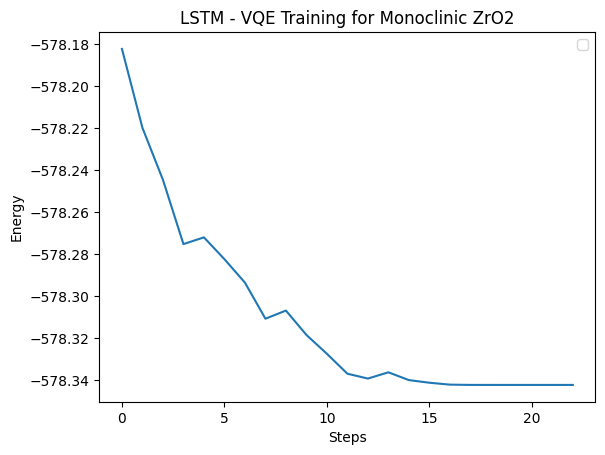

Estimated ground state energy of Monoclinic ZrO2: -578.3423108452891


In [82]:
# 绘制能量变化曲线
plt.figure()
plt.plot(energy_list)
plt.title('LSTM - VQE Training for Monoclinic ZrO2', fontsize=12)
plt.legend()
plt.xlabel('Steps', fontsize=10)
plt.ylabel('Energy', fontsize=10)
#plt.savefig('lstm_vqe_lih_energy.png')
plt.show()

print(f"Estimated ground state energy of Monoclinic ZrO2: {energy_list[-1]}")

In [83]:
energy_list

[-578.182134547028,
 -578.2197729241327,
 -578.2445321787667,
 -578.2751686473023,
 -578.2719670283793,
 -578.2823661884963,
 -578.2935383038681,
 -578.3107397744334,
 -578.3068724742943,
 -578.3184764641369,
 -578.3274792800023,
 -578.3369682021648,
 -578.339277039919,
 -578.3363003198053,
 -578.3400133517518,
 -578.3412628820864,
 -578.3421753718445,
 -578.3423047145319,
 -578.3423103886098,
 -578.3423108284744,
 -578.3423108449332,
 -578.3423108452027,
 -578.3423108452891]

In [36]:
energy_list

[-577.6495368001697,
 -578.172120075759,
 -578.2530403728119,
 -578.2908914454727,
 -578.2707378519632,
 -578.3091270743191,
 -578.3319102531357,
 -578.335321037067,
 -578.3368662201602,
 -578.3394646550095,
 -578.3419434811514,
 -578.3422778861625,
 -578.3423095809684,
 -578.3423061426437,
 -578.3423106842079,
 -578.3423108368895,
 -578.3423108447697,
 -578.3423108452862]

## 下面这个是一个比较好的 3轨道优化结果，27,28,29o 2e

In [84]:
energy_list      ##一个比较好的结果

[-578.182134547028,
 -578.2197729241327,
 -578.2445321787667,
 -578.2751686473023,
 -578.2719670283793,
 -578.2823661884963,
 -578.2935383038681,
 -578.3107397744334,
 -578.3068724742943,
 -578.3184764641369,
 -578.3274792800023,
 -578.3369682021648,
 -578.339277039919,
 -578.3363003198053,
 -578.3400133517518,
 -578.3412628820864,
 -578.3421753718445,
 -578.3423047145319,
 -578.3423103886098,
 -578.3423108284744,
 -578.3423108449332,
 -578.3423108452027,
 -578.3423108452891]

In [87]:
L1=[-577.6495368001697,
 -578.172120075759,
 -578.2530403728119,
 -578.2908914454727,
 -578.2707378519632,
 -578.3091270743191,
 -578.3319102531357,
 -578.335321037067,
 -578.3368662201602,
 -578.3394646550095,
 -578.3419434811514,
 -578.3422778861625,
 -578.3423095809684,
 -578.3423061426437,
 -578.3423106842079,
 -578.3423108368895,
 -578.3423108447697,
 -578.3423108452862]

/tmp/ipykernel_814403/3920743744.py:5: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


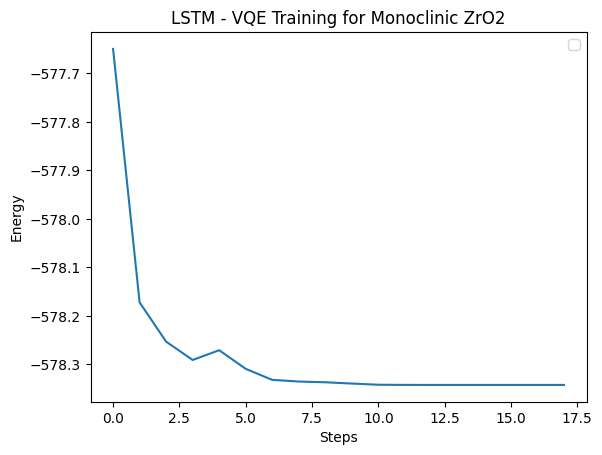

Estimated ground state energy of Monoclinic ZrO2: -578.3423108452862


In [88]:
# 绘制能量变化曲线
plt.figure()
plt.plot(L1)
plt.title('LSTM - VQE Training for Monoclinic ZrO2', fontsize=12)
plt.legend()
plt.xlabel('Steps', fontsize=10)
plt.ylabel('Energy', fontsize=10)
#plt.savefig('lstm_vqe_lih_energy.png')
plt.show()

print(f"Estimated ground state energy of Monoclinic ZrO2: {L1[-1]}")

## 4轨道

In [91]:
ansatz_circuit, \
init_amplitudes, \
ansatz_parameter_names, \
hamiltonian_QubitOp, \
n_qubits, n_electrons = generate_uccsd(ZrO2d, threshold=-1,active_space_start=22, active_space_stop=26)

In [92]:
n_electrons

4

In [93]:
hartreefock_wfn_circuit = Circuit([X.on(i) for i in range(n_electrons)])
total_circuit = hartreefock_wfn_circuit + ansatz_circuit
total_circuit.summary()
print("Number of parameters: %d" % (len(ansatz_parameter_names)))

                          Circuit Summary                           
╭──────────────────────┬───────────────────────────────────────────╮
│ Info                 │ value                                     │
├──────────────────────┼───────────────────────────────────────────┤
│ Number of qubit      │ 8                                         │
├──────────────────────┼───────────────────────────────────────────┤
│ Total number of gate │ 2692                                      │
│ Barrier              │ 640                                       │
│ Noise Channel        │ 0                                         │
│ Measurement          │ 0                                         │
├──────────────────────┼───────────────────────────────────────────┤
│ Parameter gate       │ 160                                       │
│ 14 ansatz parameters │ p0, p4, p1, p5, p2, p6, p3, p7, p8, p9... │
╰──────────────────────┴───────────────────────────────────────────╯

Number of parameters: 14


In [94]:
sim = Simulator('mqvector', total_circuit.n_qubits)
molecule_pqc = sim.get_expectation_with_grad(Hamiltonian(hamiltonian_QubitOp), total_circuit)

In [124]:
import numpy as np

n_params = len(total_circuit.params_name)
#p0 = np.zeros(n_params)
p0 = np.random.uniform(0, 2*np.pi, n_params)
#f, g = molecule_pqc(p0)
#print("Energy: ", f, "\nshape: ", f.shape, '\n')
#print("Gradient: ", g, "\nshape: ", g.shape)

def fun(p0, molecule_pqc, energy_list=None):
    f, g = molecule_pqc(p0)
    f = np.real(f)[0, 0]
    g = np.real(g)[0, 0]
    if energy_list is not None:
        energy_list.append(f)
        if len(energy_list) % 5 == 0:
            print(f"Step: {len(energy_list)},\tenergy: {f}")
    return f, g

In [125]:
from scipy.optimize import minimize

energy_list = []
res = minimize(fun, p0, args=(molecule_pqc, energy_list), method='bfgs', jac=True)

Step: 5,	energy: -578.2957324497091
Step: 10,	energy: -578.3447829581171
Step: 15,	energy: -578.3508504473133
Step: 20,	energy: -578.351069462821
Step: 25,	energy: -578.3511281787423
Step: 30,	energy: -578.3511303206791
Step: 35,	energy: -578.3511368735675
Step: 40,	energy: -578.3511800643445
Step: 45,	energy: -578.3512381836011
Step: 50,	energy: -578.3512923475857
Step: 55,	energy: -578.3512978754474
Step: 60,	energy: -578.3513221079174
Step: 65,	energy: -578.3513270399745
Step: 70,	energy: -578.3513307047853
Step: 75,	energy: -578.3513507406117
Step: 80,	energy: -578.3513510881509
Step: 85,	energy: -578.3513511092896
Step: 90,	energy: -578.3513511438315
Step: 95,	energy: -578.3513519966014
Step: 100,	energy: -578.3513597403619
Step: 105,	energy: -578.3513662133553
Step: 110,	energy: -578.3513665261869


/tmp/ipykernel_814403/443170907.py:5: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


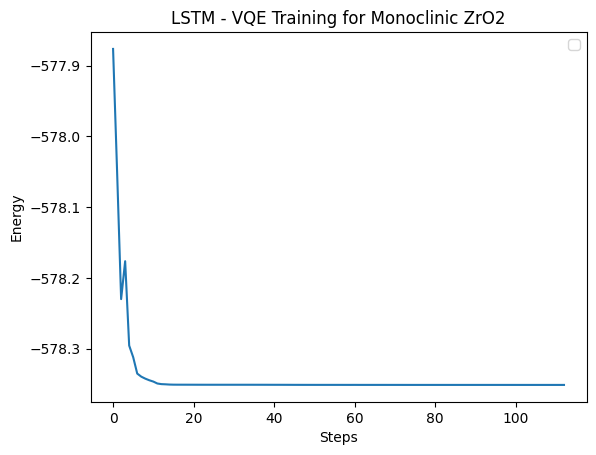

Estimated ground state energy of Monoclinic ZrO2: -578.3513665290346


In [126]:
# 绘制能量变化曲线
plt.figure()
plt.plot(energy_list)
plt.title('LSTM - VQE Training for Monoclinic ZrO2', fontsize=12)
plt.legend()
plt.xlabel('Steps', fontsize=10)
plt.ylabel('Energy', fontsize=10)
#plt.savefig('lstm_vqe_lih_energy.png')
plt.show()

print(f"Estimated ground state energy of Monoclinic ZrO2: {energy_list[-1]}")

In [ ]:
-578.3513665290346

In [127]:
energy_list

[-577.8765328478219,
 -578.0500284317227,
 -578.2301010765981,
 -578.1765165176333,
 -578.2957324497091,
 -578.3122446894754,
 -578.3353382394818,
 -578.3396727902773,
 -578.3424959452504,
 -578.3447829581171,
 -578.3466438755046,
 -578.3493636115969,
 -578.3502402936763,
 -578.3504963354058,
 -578.3508504473133,
 -578.3509978130614,
 -578.351035891551,
 -578.3510492221458,
 -578.3510568462918,
 -578.351069462821,
 -578.3510884387144,
 -578.3511057398102,
 -578.351117985245,
 -578.3511253359649,
 -578.3511281787423,
 -578.3511294002518,
 -578.3511298272928,
 -578.3511300014877,
 -578.3511301418685,
 -578.3511303206791,
 -578.3511306149206,
 -578.3511311286353,
 -578.3511320585044,
 -578.3511337666275,
 -578.3511368735675,
 -578.3511420393447,
 -578.3511467985827,
 -578.3511523006881,
 -578.3511624712357,
 -578.3511800643445,
 -578.3511905370849,
 -578.351193805248,
 -578.3512077235442,
 -578.3512227466517,
 -578.3512381836011,
 -578.3512623278175,
 -578.3512724906363,
 -578.35128405663

## 一个比较好的4轨道优化结果 26,27,28,29o 4e

In [128]:
L4=[-577.8765328478219,-578.0500284317227,-578.2301010765981,-578.1765165176333,-578.2957324497091,-578.3122446894754,-578.3353382394818,
 -578.3396727902773,-578.3424959452504,-578.3447829581171,-578.3466438755046,-578.3493636115969,-578.3502402936763,-578.3504963354058,
 -578.3508504473133,-578.3509978130614,-578.351035891551,-578.3510492221458,-578.3510568462918,-578.351069462821,-578.3510884387144,-578.3511057398102,
 -578.351117985245,-578.3511253359649,-578.3511281787423,-578.3511294002518,-578.3511298272928,-578.3511300014877,-578.3511301418685,-578.3511303206791,
 -578.3511306149206,-578.3511311286353,-578.3511320585044,-578.3511337666275,-578.3511368735675,-578.3511420393447,-578.3511467985827,
 -578.3511523006881,-578.3511624712357,-578.3511800643445,-578.3511905370849,-578.351193805248,-578.3512077235442,-578.3512227466517,-578.3512381836011,-578.3512623278175,
 -578.3512724906363,-578.3512840566392,-578.3512882148626,-578.3512923475857,-578.3512952923369,-578.3512961182087,-578.3512964565507,
 -578.3512969486259,-578.3512978754474,-578.3512996034211,-578.3513026825835,-578.3513076407642,-578.3513136654028,-578.3513221079174,
 -578.3513006860861,-578.3513260815338,-578.3513264749416,-578.3513269061995,-578.3513270399745,-578.3513272106712,-578.3513274998398,
 -578.3513280201278,-578.3513289732272,-578.3513307047853,-578.3513337349513,-578.3513385500238,-578.351344064514,-578.3513478108704,
 -578.3513507406117,-578.351351061515,-578.351351077892,-578.3513510847794,-578.351351086089,-578.3513510881509,-578.351351091463,-578.3513510966026,
 -578.3513511020835,-578.3513511060256,-578.3513511092896,-578.3513511100432,-578.3513511114958,-578.3513511158151,-578.351351125701,
 -578.3513511438315,-578.3513511778904,-578.3513512422453,-578.3513513634076,-578.3513515887341,-578.3513519966014,-578.3513526883789,
 -578.3513537047746,-578.3513552729491,-578.351357088422,-578.3513597403619,-578.3513636122138,-578.3513653516623,-578.3513658481899,
 -578.351366157877,-578.3513662133553,-578.3513663120042,-578.3513664572554,-578.351366512523,-578.3513665194888,-578.3513665261869,-578.351366527845,
 -578.3513665287162,-578.3513665290346]

In [35]:
Menergy4 = energy_list

## 5轨道，22,23,24,25,26

In [129]:
ansatz_circuit, \
init_amplitudes, \
ansatz_parameter_names, \
hamiltonian_QubitOp, \
n_qubits, n_electrons = generate_uccsd(ZrO2d, threshold=-1,active_space_start=22, active_space_stop=27)

In [130]:
n_electrons

4

In [131]:
hartreefock_wfn_circuit = Circuit([X.on(i) for i in range(n_electrons)])
total_circuit = hartreefock_wfn_circuit + ansatz_circuit
total_circuit.summary()
print("Number of parameters: %d" % (len(ansatz_parameter_names)))

                           Circuit Summary                           
╭──────────────────────┬────────────────────────────────────────────╮
│ Info                 │ value                                      │
├──────────────────────┼────────────────────────────────────────────┤
│ Number of qubit      │ 10                                         │
├──────────────────────┼────────────────────────────────────────────┤
│ Total number of gate │ 6588                                       │
│ Barrier              │ 1440                                       │
│ Noise Channel        │ 0                                          │
│ Measurement          │ 0                                          │
├──────────────────────┼────────────────────────────────────────────┤
│ Parameter gate       │ 360                                        │
│ 27 ansatz parameters │ p0, p6, p1, p7, p2, p8, p3, p9, p4, p10... │
╰──────────────────────┴────────────────────────────────────────────╯

Number of parameters: 27


In [132]:
sim = Simulator('mqvector', total_circuit.n_qubits)
molecule_pqc = sim.get_expectation_with_grad(Hamiltonian(hamiltonian_QubitOp), total_circuit)

In [197]:
import numpy as np

n_params = len(total_circuit.params_name)
#p0 = np.zeros(n_params)
p0 = np.random.uniform(0, 2*np.pi, n_params)
#f, g = molecule_pqc(p0)
#print("Energy: ", f, "\nshape: ", f.shape, '\n')
#print("Gradient: ", g, "\nshape: ", g.shape)

def fun(p0, molecule_pqc, energy_list=None):
    f, g = molecule_pqc(p0)
    f = np.real(f)[0, 0]
    g = np.real(g)[0, 0]
    if energy_list is not None:
        energy_list.append(f)
        if len(energy_list) % 5 == 0:
            print(f"Step: {len(energy_list)},\tenergy: {f}")
    return f, g

In [198]:
from scipy.optimize import minimize

energy_list = []
res = minimize(fun, p0, args=(molecule_pqc, energy_list), method='bfgs', jac=True)

Step: 5,	energy: -577.715173326868
Step: 10,	energy: -578.1665466121771
Step: 15,	energy: -578.1782640149346
Step: 20,	energy: -578.1783242974388
Step: 25,	energy: -578.1786982988457
Step: 30,	energy: -578.1788703734608
Step: 35,	energy: -578.1794173759649
Step: 40,	energy: -578.1801092496931
Step: 45,	energy: -578.180924733802
Step: 50,	energy: -578.1815402058614
Step: 55,	energy: -578.1819427128376
Step: 60,	energy: -578.1820678208474
Step: 65,	energy: -578.1828928605784
Step: 70,	energy: -578.1865892350229
Step: 75,	energy: -578.1913947293416
Step: 80,	energy: -578.2092383356261
Step: 85,	energy: -578.2527747943748
Step: 90,	energy: -578.3137772175544
Step: 95,	energy: -578.3279428324978
Step: 100,	energy: -578.3339727854278
Step: 105,	energy: -578.3371050023122
Step: 110,	energy: -578.3421105147002
Step: 115,	energy: -578.342352229227
Step: 120,	energy: -578.3424695631971
Step: 125,	energy: -578.3425012119727
Step: 130,	energy: -578.3425238124725
Step: 135,	energy: -578.34254527049

/tmp/ipykernel_814403/443170907.py:5: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


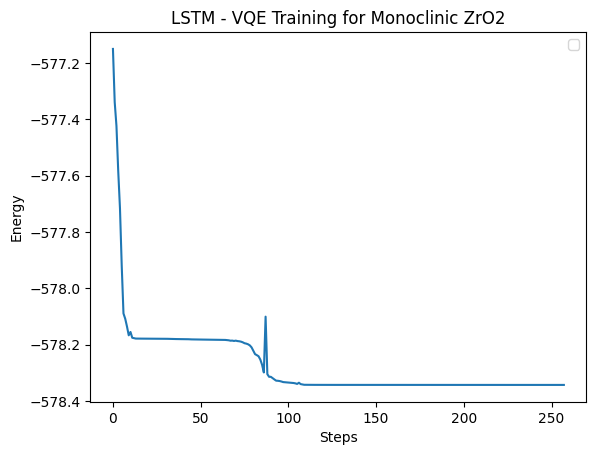

Estimated ground state energy of Monoclinic ZrO2: -578.3426108651317


In [199]:
# 绘制能量变化曲线
plt.figure()
plt.plot(energy_list)
plt.title('LSTM - VQE Training for Monoclinic ZrO2', fontsize=12)
plt.legend()
plt.xlabel('Steps', fontsize=10)
plt.ylabel('Energy', fontsize=10)
#plt.savefig('lstm_vqe_lih_energy.png')
plt.show()

print(f"Estimated ground state energy of Monoclinic ZrO2: {energy_list[-1]}")

In [ ]:
-578.3517871563753

In [200]:
print('L5=',energy_list)

L5= [-577.1500321555817, -577.3387013472047, -577.4235385072086, -577.5824847417323, -577.715173326868, -577.9190410565019, -578.0890302495108, -578.1078542728949, -578.1353030908974, -578.1665466121771, -578.1546591897503, -578.1751972424778, -578.1764933565646, -578.178077183857, -578.1782640149346, -578.1782745695352, -578.1782923562025, -578.1783113179226, -578.178315782022, -578.1783242974388, -578.1783408918134, -578.1783951313465, -578.1785071818479, -578.1785941229349, -578.1786982988457, -578.1788011872212, -578.1788345743172, -578.1788457285369, -578.1788545791559, -578.1788703734608, -578.178899594705, -578.1789540294055, -578.1790537782267, -578.1792233031027, -578.1794173759649, -578.1795580637063, -578.1797994113252, -578.1800265027589, -578.1800807790895, -578.1801092496931, -578.1801347590117, -578.1801677028759, -578.1802329088226, -578.1804664088402, -578.180924733802, -578.1810417636033, -578.1812030821554, -578.1814037389562, -578.1814943414007, -578.1815402058614, 

## 好结果

In [115]:
L5= [-577.1500321555817, -577.3387013472047, -577.4235385072086, -577.5824847417323, -577.715173326868, -577.9190410565019, -578.0890302495108, -578.1078542728949, -578.1353030908974, -578.1665466121771, -578.1546591897503, -578.1751972424778,-578.1800265027589,-578.1890708109623, -578.1913947293416, -578.1946123678708, -578.1960131996644, -578.1983437553195, -578.2215491509121, -578.2333542482406, -578.2368847544542, -578.2409355476082, -578.2527747943748, -578.2711125923976, -578.2983198814122, -578.3044620180672, -578.3137772175544, -578.3138652060805, -578.3187115435671, -578.3231345014101, -578.3274611021302, -578.3279428324978, -578.3288505327694, -578.3304447417784, -578.3325326448783, -578.3331608933635, -578.3339727854278, -578.3344651571965, -578.3347541802198, -578.3351737266617, -578.3358820047126, -578.3371050023122, -578.3391023489603, -578.3348128073017, -578.3397235598626, -578.3407866470095, -578.3421105147002, -578.3422211685149, -578.3422567874353, -578.3422942835475, -578.3423205665226, -578.342352229227, -578.342394922672, -578.3424375519814, -578.3424569417608, -578.3424651451795, -578.3424695631971, -578.3424752812901, -578.3424842567024, -578.3424948945438, -578.3424991991105, -578.3425012119727, -578.3425033147115, -578.3425065876911, -578.3425116383809, -578.3425181824432, -578.3425238124725, -578.3425294173254, -578.3425354314786, -578.3425399000167, -578.3425422916604, -578.3425452704992, -578.3425496517794, -578.3425563871252, -578.3425630480098, -578.3425645453899, -578.3425649738435, -578.3425653729959, -578.3425660682198, -578.3425672883058, -578.3425693298353, -578.3425722075759, -578.3425739261568, -578.3425751386474, -578.3425760213297, -578.3425771564155, -578.3425789954864, -578.3425817958989, -578.342584301519, -578.3425851796395, -578.3425853536734, -578.3425853666416, -578.3425853691375, -578.34258537055, -578.3425853710494, -578.3425853713037, -578.3425853717239, -578.3425853724747, -578.3425853738646, -578.342585376445, -578.3425853812105, -578.3425853898916, -578.3425854054112, -578.3425854325505, -578.3425854791858, -578.3425855592701, -578.3425856984261, -578.3425859318378, -578.3425861982047, -578.3425866862462, -578.3425875078012, -578.342588476397, -578.342586654453, -578.3425888021632, -578.3425892598082, -578.3425896724256, -578.3425901025252, -578.3425906028798, -578.342591408244, -578.3425901845654, -578.342591677788, -578.3425919744534, -578.342592202615, -578.3425922159355, -578.3425922419881, -578.3425923285567, -578.3425924956763, -578.34259266618, -578.3425929334619, -578.3425933778012, -578.3425941410212, -578.3425955766761, -578.3425750165418, -578.3425958766225, -578.342596018459, -578.342596272235, -578.3425966638961, -578.3425968472757, -578.3425970514731, -578.3425972962085, -578.3425977063264, -578.3425979647712, -578.3425980296689, -578.3425984228949, -578.3425987673356, -578.3425986979069, -578.3425988739359, -578.3425990434339, -578.3425993020123, -578.342599507966, -578.3425997660249, -578.3425999277191, -578.3426000935644, -578.3426003465805, -578.3426006720307, -578.3426011360651, -578.3426015296799, -578.342601722986, -578.3426020835011, -578.3426013964787, -578.3426022525778, -578.342602401729, -578.3426025252672, -578.3426027129944, -578.3426029163768, -578.3426029895601, -578.3426030562658, -578.3426032703003, -578.3426036263493, -578.342604196829, -578.3426047215736, -578.3426054832411, -578.3426064499946, -578.342607510422, -578.3426072574802, -578.3426076801817, -578.3426079086005, -578.3426079914318, -578.3426080009242, -578.3426080141737, -578.3426080304096, -578.3426080590598, -578.3426081137, -578.3426082188735, -578.3426085333938, -578.3426090785799, -578.3426098092747, -578.3426105359727, -578.3426107474377, -578.3426106925976, -578.3426108297725, -578.342610855403, -578.3426108623333, -578.3426108645787, -578.3426108651317]


In [59]:
Menergy5 = energy_list

## 6轨道，21,22,23,24,25,26

In [201]:
ansatz_circuit, \
init_amplitudes, \
ansatz_parameter_names, \
hamiltonian_QubitOp, \
n_qubits, n_electrons = generate_uccsd(ZrO2d, threshold=-1,active_space_start=21, active_space_stop=27)

In [202]:
n_electrons

6

In [203]:
hartreefock_wfn_circuit = Circuit([X.on(i) for i in range(n_electrons)])
total_circuit = hartreefock_wfn_circuit + ansatz_circuit
total_circuit.summary()
print("Number of parameters: %d" % (len(ansatz_parameter_names)))

                            Circuit Summary                             
╭──────────────────────┬───────────────────────────────────────────────╮
│ Info                 │ value                                         │
├──────────────────────┼───────────────────────────────────────────────┤
│ Number of qubit      │ 12                                            │
├──────────────────────┼───────────────────────────────────────────────┤
│ Total number of gate │ 16338                                         │
│ Barrier              │ 3312                                          │
│ Noise Channel        │ 0                                             │
│ Measurement          │ 0                                             │
├──────────────────────┼───────────────────────────────────────────────┤
│ Parameter gate       │ 828                                           │
│ 54 ansatz parameters │ p0, p9, p1, p10, p2, p11, p3, p12, p4, p13... │
╰──────────────────────┴───────────────────────────────────────────────╯

Number of parameters: 54


In [214]:
sim = Simulator('mqvector', total_circuit.n_qubits)
molecule_pqc = sim.get_expectation_with_grad(Hamiltonian(hamiltonian_QubitOp), total_circuit)

In [217]:
import numpy as np

n_params = len(total_circuit.params_name)
#p0 = np.zeros(n_params)
p0 = np.random.uniform(0, 2*np.pi, n_params)
#f, g = molecule_pqc(p0)
#print("Energy: ", f, "\nshape: ", f.shape, '\n')
#print("Gradient: ", g, "\nshape: ", g.shape)

def fun(p0, molecule_pqc, energy_list=None):
    f, g = molecule_pqc(p0)
    f = np.real(f)[0, 0]
    g = np.real(g)[0, 0]
    if energy_list is not None:
        energy_list.append(f)
        if len(energy_list) % 5 == 0:
            print(f"Step: {len(energy_list)},\tenergy: {f}")
    return f, g

In [218]:
from scipy.optimize import minimize

energy_list = []
res = minimize(fun, p0, args=(molecule_pqc, energy_list), method='bfgs', jac=True)

Step: 5,	energy: -577.332483866488
Step: 10,	energy: -578.2526983276879
Step: 15,	energy: -578.3137039373074
Step: 20,	energy: -578.3298497832589
Step: 25,	energy: -578.330254762672
Step: 30,	energy: -578.3302975393395
Step: 35,	energy: -578.330306897305
Step: 40,	energy: -578.3304341813947
Step: 45,	energy: -578.3305429439353
Step: 50,	energy: -578.3305515913116
Step: 55,	energy: -578.3306201760172
Step: 60,	energy: -578.3306308095987
Step: 65,	energy: -578.3306464457269
Step: 70,	energy: -578.3307099183737
Step: 75,	energy: -578.3307110974628
Step: 80,	energy: -578.3307224959601
Step: 85,	energy: -578.3307646553859
Step: 90,	energy: -578.3228763257259
Step: 95,	energy: -578.3310760523001
Step: 100,	energy: -578.3311092222333
Step: 105,	energy: -578.3311296111814
Step: 110,	energy: -578.3312130726672
Step: 115,	energy: -578.331213693507
Step: 120,	energy: -578.3312179167626
Step: 125,	energy: -578.3312283991265
Step: 130,	energy: -578.3312288358194
Step: 135,	energy: -578.331235799442

/tmp/ipykernel_814403/443170907.py:5: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


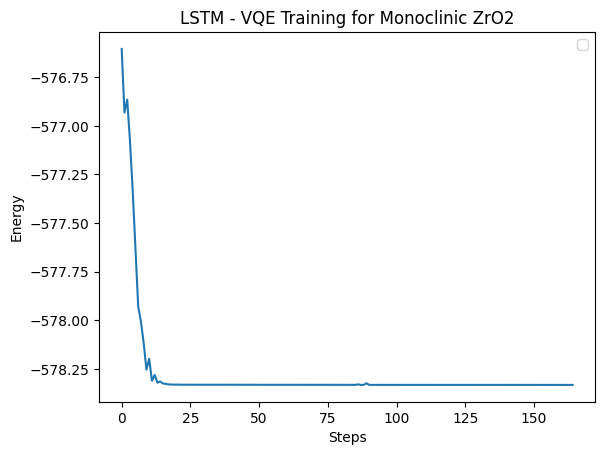

Estimated ground state energy of Monoclinic ZrO2: -578.3312470289621


In [221]:
# 绘制能量变化曲线
plt.figure()
plt.plot(energy_list)
plt.title('LSTM - VQE Training for Monoclinic ZrO2', fontsize=12)
plt.legend()
plt.xlabel('Steps', fontsize=10)
plt.ylabel('Energy', fontsize=10)
#plt.savefig('lstm_vqe_lih_energy.png')
plt.show()

print(f"Estimated ground state energy of Monoclinic ZrO2: {energy_list[-1]}")

In [ ]:
-578.3557534736252

In [220]:
print('L6=',energy_list)

L6= [-576.605029719118, -576.931891564637, -576.8654391627355, -577.0761637768662, -577.332483866488, -577.631472195477, -577.9273868874791, -578.0060580244306, -578.1171017031669, -578.2526983276879, -578.1968264011516, -578.3096628759041, -578.2801864120631, -578.3197600918746, -578.3137039373074, -578.3236261264034, -578.3257518736674, -578.3284583405808, -578.329087707257, -578.3298497832589, -578.329540083714, -578.3299811346761, -578.3301324479419, -578.3302060536369, -578.330254762672, -578.3302746515816, -578.3302875688212, -578.3302928635079, -578.3302955002886, -578.3302975393395, -578.3302996127395, -578.3303007705446, -578.330301782434, -578.3303035782377, -578.330306897305, -578.3303131207441, -578.3303247825329, -578.3303462330691, -578.3303832251868, -578.3304341813947, -578.3304782349217, -578.3305235864322, -578.3305360343567, -578.3305413134767, -578.3305429439353, -578.3305434416245, -578.330544148456, -578.3305453798201, -578.3305475936464, -578.3305515913116, -578.

In [103]:
L6=[-605.672301047877,-606.5444939553223,-607.4516068626691,-606.8206153485895,-607.7738003404322,-608.0930567990422,-607.9429015214613,-608.1082359419971,
 -608.10264535389,-608.1145218989572,-608.1154192311499,-608.1169598460074,-608.1187802517908,-608.1152184183702,-608.1192471580546,
 -608.1194431770058,-608.1195144395804,-608.1195830964606,-608.119602680474,-608.1196115682925,-608.1196140338002,-608.1196148442001,
 -608.1196151903938,-608.1196163470137,-608.1196174068508,-608.1196184315328,-608.1196194393417,-608.1196198404411,-608.1196199420286,-608.1196154447807,
 -608.1196254497687,-608.1196354589691,-608.1196654759829,-608.11968155072706,-608.119695564191,-608.1197056664327,-608.1197158491435,
 -608.1197261824265,-608.1197368374421,-608.1197405240147,-608.11975358861655,-608.1197610327018,-608.1197899881944,-608.11939234694424,
 -608.11981858447262,-608.119820405908,-608.1198411974679,-608.1198527011782,-608.1199024568, -608.11993698777984,
 -608.11995699310334,-608.11996700181475,-608.11996751531499,-608.119967703334617,-608.119968705019383,-608.119969705835852,-608.11997015947544,-608.119986705954737,
   -608.1199902167,-608.119993986736,-608.12000377656,-608.1200560844345]

/tmp/ipykernel_798557/2289154007.py:5: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


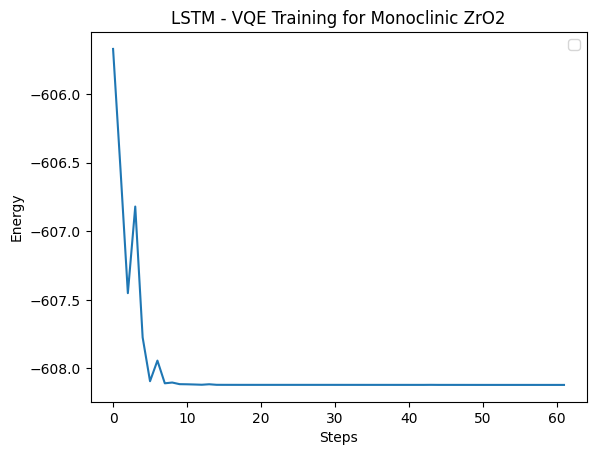

Estimated ground state energy of Monoclinic ZrO2: -608.1200560844345


In [104]:
# 绘制能量变化曲线
plt.figure()
plt.plot(L6)
plt.title('LSTM - VQE Training for Monoclinic ZrO2', fontsize=12)
plt.legend()
plt.xlabel('Steps', fontsize=10)
plt.ylabel('Energy', fontsize=10)
#plt.savefig('lstm_vqe_lih_energy.png')
plt.show()

print(f"Estimated ground state energy of Monoclinic ZrO2: {L6[-1]}")

In [136]:
L6=[-604.0002159008357,-605.0022810188616,-604.5509883490627,-605.5699723620663,-605.9143813186827,-606.1785268678395,-606.4679150344735,
-606.6031343857064,-606.708327627045,-606.855908805653,-607.082280290574,-607.3231046807604,-607.0461674790116,-607.4111269012307,
 -607.5173707318992,-607.5547479932594,-607.6144983744014,-607.7169176162487,-607.8619947912977,-607.684276371614,-607.9194987017919,
-607.9819184508173,-608.022782087438,-608.0594850487275,-608.0724003492776,-608.0877550138488,-608.0942819545259,-608.0984852774203,-608.1005361831996,-608.1034312880773,
 -608.1071124182358,-608.1100949832506,-608.1129654401137,-608.1154036088737,-608.1165320716494,-608.1173012721271,-608.1176778385843,
 -608.1179213069967,-608.118167705678,-608.1184204523523,-608.1186063275215,-608.1186856354029,-608.1187366424463,-608.118892308235,-608.1189846581336,
 -608.1190958285723,-608.1192350127545,-608.119421029637,-608.1194593599151,-608.1195123574197,-608.1195326496365,-608.1195411404894,
 -608.1195528393284,-608.1195719713877,-608.1195931770507,-608.119597514687,-608.1196041119626,-608.1196064689734,-608.1196074000156,
 -608.1196077669988,-608.1196082432696,-608.1196083645185,-608.1196083879116,-608.1196083898524,-608.1196083911369,-608.119608391331,
 -608.1196083916882,-608.1196083923692,-608.1196083936285,-608.1196083959247,-608.119608399967,-608.1196084066042,-608.1196084164322,
 -608.119608426772,-608.1196084392192,-608.1196084451785,-608.1196084458404,-608.1196084459093,-608.1196084459457]

[-604.0002159008357,
 -605.0022810188616,
 -604.5509883490627,
 -605.5699723620663,
 -605.9143813186827,
 -606.1785268678395,
 -606.4679150344735,
 -606.6031343857064,
 -606.708327627045,
 -606.855908805653,
 -607.082280290574,
 -607.3231046807604,
 -607.0461674790116,
 -607.4111269012307,
 -607.5173707318992,
 -607.5547479932594,
 -607.6144983744014,
 -607.7169176162487,
 -607.8619947912977,
 -607.684276371614,
 -607.9194987017919,
 -607.9819184508173,
 -608.022782087438,
 -608.0594850487275,
 -608.0724003492776,
 -608.0877550138488,
 -608.0942819545259,
 -608.0984852774203,
 -608.1005361831996,
 -608.1034312880773,
 -608.1071124182358,
 -608.1100949832506,
 -608.1129654401137,
 -608.1154036088737,
 -608.1165320716494,
 -608.1173012721271,
 -608.1176778385843,
 -608.1179213069967,
 -608.118167705678,
 -608.1184204523523,
 -608.1186063275215,
 -608.1186856354029,
 -608.1187366424463,
 -608.118892308235,
 -608.1189846581336,
 -608.1190958285723,
 -608.1192350127545,
 -608.119421029637,


/tmp/ipykernel_798557/443170907.py:5: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


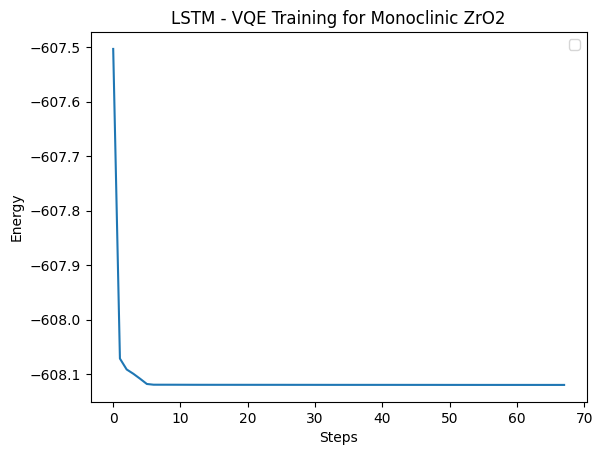

Estimated ground state energy of Monoclinic ZrO2: -608.1200560772278


In [116]:
# 绘制能量变化曲线
plt.figure()
plt.plot(energy_list)
plt.title('LSTM - VQE Training for Monoclinic ZrO2', fontsize=12)
plt.legend()
plt.xlabel('Steps', fontsize=10)
plt.ylabel('Energy', fontsize=10)
#plt.savefig('lstm_vqe_lih_energy.png')
plt.show()

print(f"Estimated ground state energy of Monoclinic ZrO2: {energy_list[-1]}")